# Assignment 1: Heart Disease Data Profiling

**Course:** TTTC3213 Data Engineering

**Dataset:** Heart Disease Prediction Dataset

## Group Members
1. NUR ATIERAH BINTI MOHD ALI HANAFIAH (A212621)
2. NOOR DINAH BINTI MD SAIFUL FADLY (A212710)
3. NURIN IMANINA BINTI ZAHARUDDIN (A212774)
4. NUR IRDINA SAFIYA BINTI ROSLAN (A213601)

## 1. Scenario

A healthcare clinic aims to improve the quality of patient cardiovascular records before using them for heart disease risk assessment. The dataset contains potential data quality issues such as invalid zero values, outliers, and demographic imbalance. This analysis aims to identify which features require cleaning and how these issues may affect the
reliability of the dataset.

## 2. Data Source

Dataset: Heart Failure Prediction Dataset

Source: Kaggle
URL: https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction

The dataset was obtained as a CSV file and uploaded to Google Colab for data profiling and quality assessment.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("heart.csv")
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [ ]:
print("Dataset shape:", df.shape)
df.info()
display(df.describe(include="all"))

Dataset shape: (918, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
count,918.000000,918,918,918.000000,918.000000,918.000000,918,918.000000,918,918.000000,918,918.000000
unique,NaN,2,4,NaN,NaN,NaN,3,NaN,2,NaN,3,NaN
top,NaN,M,ASY,NaN,NaN,NaN,Normal,NaN,N,NaN,Flat,NaN
freq,NaN,725,496,NaN,NaN,NaN,552,NaN,547,NaN,460,NaN
mean,53.510893,NaN,NaN,132.396514,198.799564,0.233115,NaN,136.809368,NaN,0.887364,NaN,0.553377
std,9.432617,NaN,NaN,18.514154,109.384145,0.423046,NaN,25.460334,NaN,1.066570,NaN,0.497414
min,28.000000,NaN,NaN,0.000000,0.000000,0.000000,NaN,60.000000,NaN,-2.600000,NaN,0.000000
25%,47.000000,NaN,NaN,120.000000,173.250000,0.000000,NaN,120.000000,NaN,0.000000,NaN,0.000000
50%,54.000000,NaN,NaN,130.000000,223.000000,0.000000,NaN,138.000000,NaN,0.600000,NaN,1.000000
75%,60.000000,NaN,NaN,140.000000,267.000000,0.000000,NaN,156.000000,NaN,1.500000,NaN,1.000000


## 3.1 Missing Values

This section examines missing values and identifies
potentially invalid zero values in the dataset.

In [ ]:
# Check actual missing values
print(df.isnull().sum())

# Check suspicious zero values
print("Cholesterol = 0:", (df["Cholesterol"] == 0).sum())
print("RestingBP = 0:", (df["RestingBP"] == 0).sum())

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64
Cholesterol = 0: 172
RestingBP = 0: 1


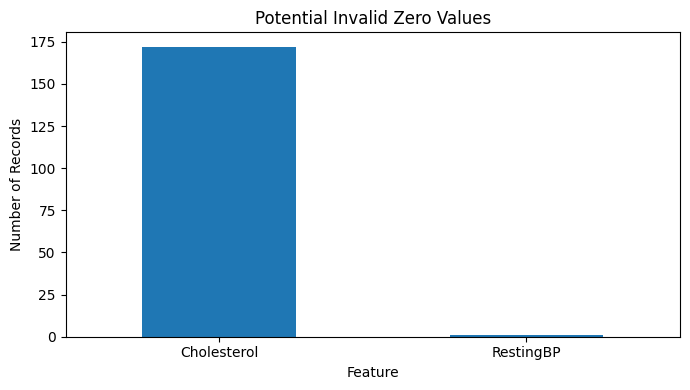

In [ ]:
### 3.1.1 Diagnostic Chart: Invalid Zero Values

zero_counts = pd.Series({
    "Cholesterol": (df["Cholesterol"] == 0).sum(),
    "RestingBP": (df["RestingBP"] == 0).sum()
})

zero_counts.plot(kind="bar", figsize=(7, 4))

plt.title("Potential Invalid Zero Values")
plt.xlabel("Feature")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Chart 1 Interpretation:** The chart shows 172 invalid zero values in Cholesterol and one in RestingBP, indicating potential missing-value placeholders that require treatment before further analysis.

In [ ]:
df_clean = df.copy()

for col in ["Cholesterol", "RestingBP"]:
    df_clean[col + "_missing_flag"] = (df_clean[col] == 0).astype(int)
    df_clean[col] = df_clean[col].replace(0, np.nan)
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Display cleaned dataset
display(df_clean.head())

# Verify missing values after handling
print("\nMissing values after cleaning:")
print(df_clean[["Cholesterol", "RestingBP"]].isnull().sum())

# Check how many values were imputed
print("\nNumber of imputed values:")
print(df_clean[["Cholesterol_missing_flag",
                "RestingBP_missing_flag"]].sum())

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease,Cholesterol_missing_flag,RestingBP_missing_flag
0,40,M,ATA,140.0,289.0,0,Normal,172,N,0.0,Up,0,0,0
1,49,F,NAP,160.0,180.0,0,Normal,156,N,1.0,Flat,1,0,0
2,37,M,ATA,130.0,283.0,0,ST,98,N,0.0,Up,0,0,0
3,48,F,ASY,138.0,214.0,0,Normal,108,Y,1.5,Flat,1,0,0
4,54,M,NAP,150.0,195.0,0,Normal,122,N,0.0,Up,0,0,0



Missing values after cleaning:
Cholesterol    0
RestingBP      0
dtype: int64

Number of imputed values:
Cholesterol_missing_flag    172
RestingBP_missing_flag        1
dtype: int64


### Missing Values Findings and Handling

- No missing values were initially detected as NaN.
- Cholesterol contained 172 zero values.
- RestingBP contained 1 zero value.
- These zeros were treated as potential missing-value
  placeholders because they are clinically implausible.
- Median imputation was applied to retain the records
  while reducing the influence of extreme values.
- Missing-value flags were created to preserve information about the original data.

## 3.2 Outlier Detection and Handling

The Interquartile Range (IQR) method was used to detect potential outliers in numerical features, including Age, RestingBP, Cholesterol, MaxHR, and Oldpeak.

In [ ]:
### 3.2.1 Diagnostic Chart: Outlier Detection

numeric_cols = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]

for col in numeric_cols:
      Q1 = df_clean[col].quantile(0.25)
      Q3 = df_clean[col].quantile(0.75)
      IQR = Q3 - Q1
      lower = Q1 - 1.5 * IQR
      upper = Q3 + 1.5 * IQR

      outliers = df_clean[
          (df_clean[col] < lower) | (df_clean[col] > upper)
      ]

      print(f"{col}: {len(outliers)} outliers")

Age: 0 outliers
RestingBP: 27 outliers
Cholesterol: 41 outliers
MaxHR: 2 outliers
Oldpeak: 16 outliers


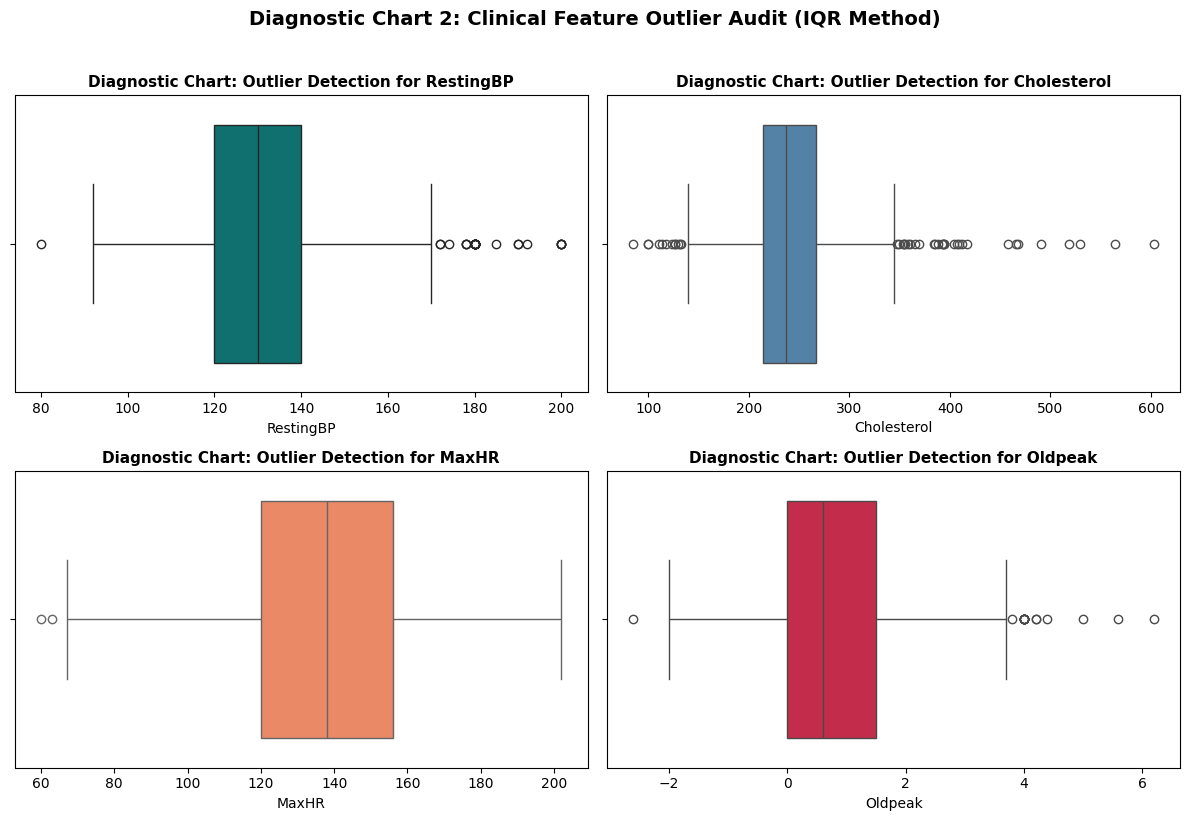

In [ ]:
# Grid 2x2
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Numerical features that have outliers
numeric_features = ["RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]
colors = ['teal', 'steelblue', 'coral', 'crimson']

# Boxplot for each features
for idx, feature in enumerate(numeric_features):
    row = idx // 2
    col = idx % 2
    sns.boxplot(x=df_clean[feature], ax=axes[row, col], color=colors[idx])
    axes[row, col].set_title(f'Diagnostic Chart: Outlier Detection for {feature}', fontsize=11, fontweight='bold')
    axes[row, col].set_xlabel(f'{feature}')

plt.suptitle('Diagnostic Chart 2: Clinical Feature Outlier Audit (IQR Method)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

**Chart 2 Interpretation:** The boxplots reveal potential outliers in RestingBP (27), Cholesterol (41), MaxHR (2), and Oldpeak (16), while Age has no detected outliers based on the IQR method.

### Outlier Detection Findings & Justification

#### 1. How Outliers Were Detected
Outliers were detected using a combined quantitative and visual approach:
- **Quantitatively, we applied the IQR Method (Interquartile Range)**: Calculated using the formula $IQR = Q3 - Q1$. Boundaries were set at $1.5 \times IQR$ below $Q1$ (lower boundary) and above $Q3$ (upper boundary).
- **Visually, we applied the Boxplots**: Generated in Diagnostic Chart 2 to visually verify the distribution and identify extreme observations outside the whiskers.

#### 2. Detected Outlier Counts
Applying the IQR formula to `df_clean` yielded the following outlier counts:
- **Age**: 0 outliers
- **RestingBP**: 27 outliers
- **Cholesterol**: 41 outliers
- **MaxHR**: 2 outliers
- **Oldpeak**: 16 outliers

#### 3. Handling Decision & Justification

**Decision**: We chose to **retain (keep) all identified outliers** without applying removal or capping (Winsorization).

**Justification**:
-  **Clinical Diagnostic Relevance:** In medical datasets, extreme readings are strong clinical signals rather than useless noise. For instance, severe ST depression (`Oldpeak`) and significantly elevated blood pressure or cholesterol levels are primary physiological markers of acute cardiovascular disease. Deleting or capping these values would erase high-risk patient profiles that predictive models need to learn.
* **Data Validity Post-Imputation:** After handling invalid zero placeholders in Cholesterol and RestingBP, the remaining outliers may represent genuine clinical measurements. However, their validity cannot be fully confirmed without additional clinical verification.
* **Preserving Real-World Variance:** Retaining these extreme clinical measurements prevents artificial variance compression and ensures downstream models remain realistic when scoring high-risk patient cases.

## 3.3 Other Data Quality Issues



This section evaluates additional aspects of data integrity across the dataset, including:
1. **Duplicate Records**: Identifying exact row-level duplicates.
2. **Data Types**: Verifying structural alignment between stored pandas data types (`int64`, `float64`, `object`) and variable representations.
3. **Categorical Consistency**: Checking unique category values for formatting errors, typos, or unexpected labels.
4. **Invalid Numerical & Binary Values**: Validating numerical ranges (detecting values $\le 0$) and confirming binary constraints for target and feature flags.

In [ ]:
# 1. Duplicate Records Check
dup_df = pd.DataFrame([{
    "Metric": "Duplicate Records",
    "Count": df_clean.duplicated().sum(),
    "Status": "Clean" if df_clean.duplicated().sum() == 0 else "Action Required"
}])
print("=== 1. Duplicate Records Summary ===")
display(dup_df)

# 2. Data Types Summary
dtypes_df = pd.DataFrame(df_clean.dtypes, columns=['Data Type']).reset_index()
dtypes_df.columns = ['Column Name', 'Data Type']
print("\n=== 2. Data Types Summary ===")
display(dtypes_df)

# 3. Categorical Values Frequency Summary
cat_summary = []
categorical_cols = ["Sex", "ChestPainType", "RestingECG", "ExerciseAngina", "ST_Slope"]

for col in categorical_cols:
    counts = df_clean[col].value_counts()
    for val, count in counts.items():
        cat_summary.append({
            "Column": col,
            "Category Value": val,
            "Count": count,
            "Percentage (%)": round((count / len(df_clean)) * 100, 2)
        })

print("\n=== 3. Categorical Value Counts Summary ===")
display(pd.DataFrame(cat_summary))

# 4. Invalid Numerical Values Check (Values <= 0)
num_cols = ["Age", "RestingBP", "Cholesterol", "MaxHR"]
invalid_num = []
for col in num_cols:
    invalid_count = (df_clean[col] <= 0).sum()
    invalid_num.append({
        "Feature": col,
        "Invalid Count (<= 0)": invalid_count,
        "Status": "Valid" if invalid_count == 0 else "Contains Invalid Zero/Negative"
    })

print("\n=== 4. Invalid Numerical Values Check ===")
display(pd.DataFrame(invalid_num))

# 5. Binary Columns Validation
binary_cols = ["FastingBS", "HeartDisease"]
binary_summary = []
for col in binary_cols:
    invalid_count = (~df_clean[col].isin([0, 1])).sum()
    binary_summary.append({
        "Binary Column": col,
        "Invalid Count (Not 0/1)": invalid_count,
        "Status": "Valid Binary" if invalid_count == 0 else "Invalid Categories"
    })

print("\n=== 5. Binary Columns Validation ===")
display(pd.DataFrame(binary_summary))

=== 1. Duplicate Records Summary ===


,Metric,Count,Status
0,Duplicate Records,0,Clean



=== 2. Data Types Summary ===


,Column Name,Data Type
0,Age,int64
1,Sex,object
2,ChestPainType,object
3,RestingBP,float64
4,Cholesterol,float64
5,FastingBS,int64
6,RestingECG,object
7,MaxHR,int64
8,ExerciseAngina,object
9,Oldpeak,float64



=== 3. Categorical Value Counts Summary ===


,Column,Category Value,Count,Percentage (%)
0,Sex,M,725,78.98
1,Sex,F,193,21.02
2,ChestPainType,ASY,496,54.03
3,ChestPainType,NAP,203,22.11
4,ChestPainType,ATA,173,18.85
5,ChestPainType,TA,46,5.01
6,RestingECG,Normal,552,60.13
7,RestingECG,LVH,188,20.48
8,RestingECG,ST,178,19.39
9,ExerciseAngina,N,547,59.59



=== 4. Invalid Numerical Values Check ===


,Feature,Invalid Count (<= 0),Status
0,Age,0,Valid
1,RestingBP,0,Valid
2,Cholesterol,0,Valid
3,MaxHR,0,Valid



=== 5. Binary Columns Validation ===


,Binary Column,Invalid Count (Not 0/1),Status
0,FastingBS,0,Valid Binary
1,HeartDisease,0,Valid Binary


### 3.3.1 Other Data Quality Findings & Treatment

1. **Duplicate Records**:
   - **Finding**: 0 duplicate rows detected (`df_clean.duplicated().sum() == 0`).
   - **Fix**: No action required.

2. **Data Types**:
   - **Finding**: Numerical columns (`Age`, `RestingBP`, `Cholesterol`, `MaxHR`, `Oldpeak`, `FastingBS`, `HeartDisease`) are properly assigned integer or float types. Categorical columns (`Sex`, `ChestPainType`, `RestingECG`, `ExerciseAngina`, `ST_Slope`) are stored as `object` data types.
   - **Fix**: Data types are appropriate for data profiling. (If required for machine learning models in later pipelines, object types can be encoded or converted to pandas `category`).

3. **Categorical Consistency**:
   - **Finding**: All categorical features strictly adhere to standard medical categories without formatting errors, typos, trailing whitespace, or unexpected values:
     - `Sex`: 'M' (725), 'F' (193)
     - `ChestPainType`: 'ASY' (496), 'NAP' (203), 'ATA' (173), 'TA' (46)
     - `RestingECG`: 'Normal' (552), 'LVH' (188), 'ST' (178)
     - `ExerciseAngina`: 'N' (547), 'Y' (371)
     - `ST_Slope`: 'Flat' (460), 'Up' (395), 'Down' (63)
   - **Fix**: No action required as categories are consistent.

4. **Invalid Numerical and Binary Values**:
   - **Finding**: No negative or invalid zero values remain for numerical columns (`Age`, `RestingBP`, `Cholesterol`, `MaxHR`). Binary variables (`FastingBS` and `HeartDisease`) strictly contain valid `0` and `1` values.
   - **Clinical Note**: Binary `0` values (such as `HeartDisease = 0` representing absence of disease or `FastingBS = 0`) are clinically valid target/feature indicators and are not treated as missing values.
   - **Fix**: No action required.

## 4. PII and Bias Risks

This section evaluates sensitive health information,
potential privacy concerns, and demographic imbalance
within the dataset.

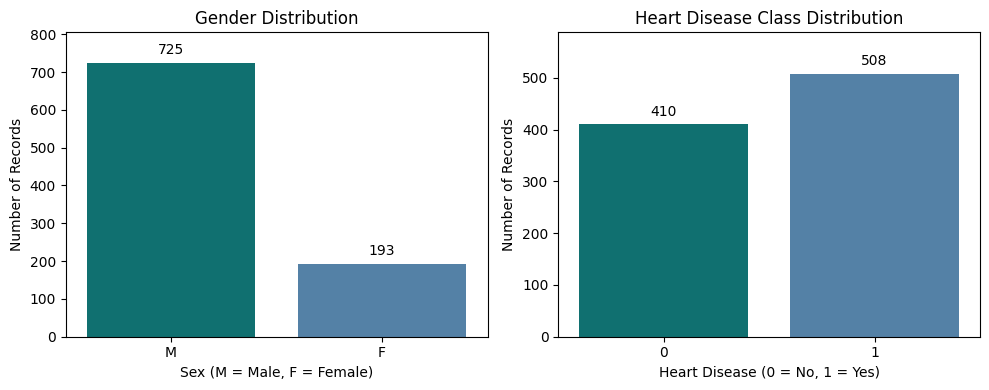

In [ ]:
### 4.1 Diagnostic Chart: Group Balance

# Create side-by-side subplots
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Same colors for both charts
colors = ['teal', 'steelblue']

# Chart 3a: Gender Distribution
sns.countplot(data=df, x="Sex", hue="Sex", ax=axes[0],
              palette=colors, legend=False,
              order=["M", "F"], hue_order=["M", "F"])

axes[0].set_title("Gender Distribution")
axes[0].set_xlabel("Sex (M = Male, F = Female)")
axes[0].set_ylabel("Number of Records")
axes[0].set_ylim(0, df["Sex"].value_counts().max() + 80)

# Chart 3b: Heart Disease Distribution
sns.countplot(data=df, x="HeartDisease", hue="HeartDisease",
              ax=axes[1], palette=colors, legend=False,
              order=[0, 1], hue_order=[0, 1])

axes[1].set_title("Heart Disease Class Distribution")
axes[1].set_xlabel("Heart Disease (0 = No, 1 = Yes)")
axes[1].set_ylabel("Number of Records")
axes[1].set_ylim(0, df["HeartDisease"].value_counts().max() + 80)

# Add labels to all bars
for ax in axes:
    for container in ax.containers:
        ax.bar_label(container, padding=4)

plt.tight_layout()
plt.show()

### Diagnostic Chart 3: Gender and Heart Disease Class Distribution

**Chart Interpretation:** The dataset shows a significant gender imbalance, with 725 male records (79.0%) and 193 female records (21.0%). However, the heart disease classes are relatively balanced, with 508 positive cases (55.3%) and 410 negative cases (44.7%).

### 4.2 PII and Bias Findings

- **PII and Sensitive Data:** The dataset does not contain direct identifiers such as names, MyKad numbers, or addresses. However, age, sex, and cardiovascular measurements are sensitive health-related attributes.

- **Sampling Bias:** The dataset combines records from several cardiovascular datasets, which may not represent the general population. The gender imbalance could also affect the generalizability of future machine learning models.

- **Bias Mitigation:** All records were retained to preserve the original distribution. Future machine learning models should be evaluated separately across demographic groups to identify potential performance differences.

- **Privacy Protection:** Access to sensitive health information should be restricted. Real patient records should be de-identified before sharing, and identifiable medical data should not be uploaded to public repositories.

### 4.3 Missing-Value Distribution by Sex

This analysis examines whether invalid cholesterol values
are distributed equally between male and female records.

In [ ]:
# Check cholesterol missingness by sex
missing_by_sex = pd.crosstab(
    df["Sex"],
    df["Cholesterol"] == 0,
    normalize="index"
) * 100

display(missing_by_sex.round(2))

Cholesterol,False,True
Sex,,
F,94.30,5.70
M,77.79,22.21


**Findings:** Cholesterol missing-value placeholders are more common among male records (22.21%) than female records (5.70%), suggesting that missingness is not evenly distributed across demographic groups.

**Mitigation:** Median imputation was applied while retaining missing-value flags. However, the potential differences between demographic groups should be considered during future machine learning evaluation.

In [ ]:
### Final Data Quality Verification

# Final checks on the cleaned dataset
print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)

print("\nRemaining missing values:")
print(df_clean.isnull().sum())

print("\nDuplicate records:")
print(df_clean.duplicated().sum())

Original shape: (918, 12)
Cleaned shape: (918, 14)

Remaining missing values:
Age                         0
Sex                         0
ChestPainType               0
RestingBP                   0
Cholesterol                 0
FastingBS                   0
RestingECG                  0
MaxHR                       0
ExerciseAngina              0
Oldpeak                     0
ST_Slope                    0
HeartDisease                0
Cholesterol_missing_flag    0
RestingBP_missing_flag      0
dtype: int64

Duplicate records:
0


## 5. Conclusion

The Heart Disease dataset is suitable for educational data profiling and developing a prototype data engineering pipeline. The analysis identified 172 invalid zero values in Cholesterol and one in RestingBP, which were handled using median imputation and missing-value flags. Statistical outliers were also detected and retained for further validation.

However, several limitations remain. Approximately 18.7% of Cholesterol records required imputation, which may affect the original data distribution. The dataset also contains a gender imbalance, with 725 male and 193 female records, potentially limiting its representativeness.

Overall, the dataset is suitable for further educational analysis and ML experimentation, but additional validation, bias assessment, and clinical review would be required before using it in real healthcare decision-making.